# Understanding Regression Metrics in scikit-learn


Regression models predict continuous numerical values such as revenue, demand, or temperature. After fitting a model, we need metrics that tell us not only whether the predictions are close to the truth, but also what kind of errors the model tends to make.

In this notebook, we train a simple regression model on a movie dataset and use it to understand the most common regression metrics in scikit-learn.


These metrics are related, but they emphasize different aspects of prediction error:

```mermaid
flowchart TD
    A[Actual values + predicted values] --> B[Absolute errors]
    A --> C[Squared errors]
    A --> D[Relative errors]
    A --> E[Explained variance]
    B --> F[MAE]
    C --> G[MSE]
    C --> H[RMSE]
    D --> I[MAPE]
    E --> J[R²]
```


## Build a Baseline Regressor


We use an artificial movie dataset. The target column `Collection` contains the amount of money a movie earned, while the remaining columns describe properties such as budget, ratings, and genre.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

In [2]:
df = pd.read_csv("data/movies.csv")
df.head()

,Marketing expense,Production expense,Multiplex coverage,Budget,Movie_length,Lead_ Actor_Rating,Lead_Actress_rating,Director_rating,Producer_rating,Critic_rating,Trailer_views,Time_taken,Twitter_hastags,Avg_age_actors,Num_multiplex,Collection,3D_available_YES,Genre_Comedy,Genre_Drama,Genre_Thriller
0,20.1264,59.62,0.462,36524.125,138.7,7.825,8.095,7.910,7.995,7.94,527367,109.60,223.840,23,494,48000,True,False,False,True
1,20.5462,69.14,0.531,35668.655,152.4,7.505,7.650,7.440,7.470,7.44,494055,146.64,243.456,42,462,43200,False,False,True,False
2,20.5458,69.14,0.531,39912.675,134.6,7.485,7.570,7.495,7.515,7.44,547051,147.88,2022.400,38,458,69400,False,True,False,False
3,20.6474,59.36,0.542,38873.890,119.3,6.895,7.035,6.920,7.020,8.26,516279,185.36,225.344,45,472,66800,True,False,True,False
4,21.3810,59.36,0.542,39701.585,127.7,6.920,7.070,6.815,7.070,8.26,531448,176.48,225.792,55,395,72400,False,False,True,False


Before training, it helps to inspect the scale of the target. Most regression metrics are only meaningful relative to the size of the values we try to predict.


In [3]:
df["Collection"].describe()

count       506.000000
mean      45057.707510
std       18364.351764
min       10000.000000
25%       34050.000000
50%       42400.000000
75%       50000.000000
max      100000.000000
Name: Collection, dtype: float64

Next, we split the features from the target, create a train-test split, and fit a small decision tree regressor. A shallow tree is useful here because it is easy to train and gives us predictions that are imperfect enough to make the metrics interesting.


In [4]:
X = df.drop(columns="Collection")
y = df["Collection"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
)

reg_tree = DecisionTreeRegressor(max_depth=3, random_state=1)
reg_tree.fit(X_train, y_train)

y_pred = reg_tree.predict(X_test)

## Prediction Plot


A quick plot of actual versus predicted values gives us an intuitive first impression. We can see whether the model captures the broad pattern and whether it misses some observations by a large margin.


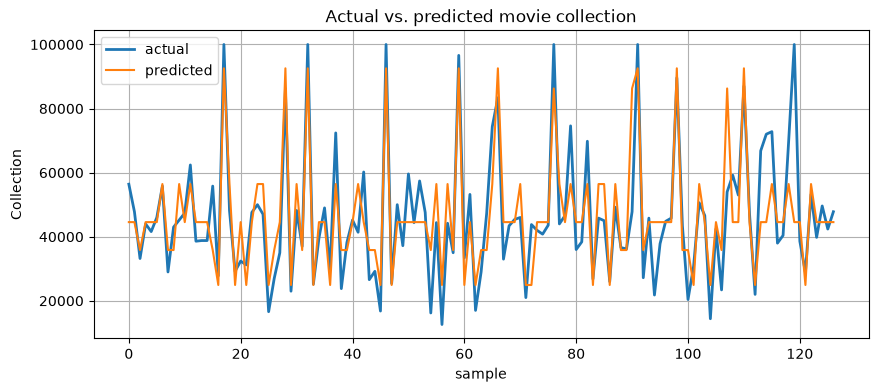

,actual,predicted
0,56400,44556.462585
1,47800,44556.462585
2,33200,35840.000000
3,44000,44556.462585
4,41600,44556.462585


In [5]:
comparison_df = pd.DataFrame(
    {
        "actual": y_test.to_numpy(),
        "predicted": y_pred,
    }
).reset_index(drop=True)

plt.figure(figsize=(10, 4))
plt.plot(comparison_df.index, comparison_df["actual"], label="actual", linewidth=2)
plt.plot(
    comparison_df.index,
    comparison_df["predicted"],
    label="predicted",
    linewidth=1.5,
)
plt.title("Actual vs. predicted movie collection")
plt.xlabel("sample")
plt.ylabel("Collection")
plt.legend()
plt.grid(True)
plt.show()

comparison_df.head()

A useful follow-up is to inspect the residuals, which are the differences between the actual and predicted values. Looking at the largest residuals shows which observations the model struggles with most.

In [6]:
comparison_df = comparison_df.assign(
    residual=comparison_df["actual"] - comparison_df["predicted"],
    absolute_error=(comparison_df["actual"] - comparison_df["predicted"]).abs(),
)

comparison_df.sort_values("absolute_error", ascending=False).head()

,actual,predicted,residual,absolute_error
119,100000,44556.462585,55443.537415,55443.537415
90,47800,86280.000000,-38480.000000,38480.000000
107,54000,86280.000000,-32280.000000,32280.000000
114,72000,44556.462585,27443.537415,27443.537415
94,21800,44556.462585,-22756.462585,22756.462585


A residual plot adds another useful perspective. If the residuals are spread widely or show a visible pattern, it can be a sign that the model is missing structure in the data.


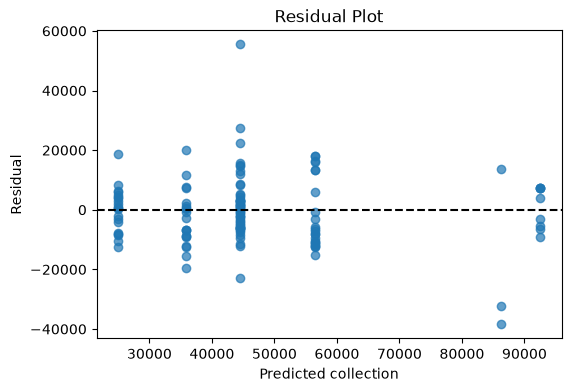

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(comparison_df["predicted"], comparison_df["residual"], alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted collection")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

The model follows the overall trend, but several predictions are still noticeably off. Regression metrics summarize those errors in different ways.


## Mean Absolute Error (MAE)


MAE is the average absolute difference between the predicted and actual values.

$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

Because it uses absolute values, every error contributes in direct proportion to its size. MAE is therefore easy to interpret in the same unit as the target variable.


In [8]:
mae = mean_absolute_error(y_test, y_pred)
print(f"MAE: {mae:,.0f}")

MAE: 8,224


An MAE of a few thousand may be acceptable or unacceptable depending on the scale of `Collection`. That is why the earlier `describe()` output matters: context determines whether the typical error is small or large.


## Mean Squared Error (MSE)


MSE averages the squared prediction errors.

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Squaring makes large errors count much more heavily than small ones, so MSE is especially sensitive to outliers.


In [9]:
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:,.0f}")

MSE: 127,600,578


If your application wants to penalize very large mistakes much more strongly than moderate ones, MSE is often a better fit than MAE.


## Root Mean Squared Error (RMSE)


RMSE is simply the square root of MSE.

$$RMSE = \sqrt{MSE}$$

It keeps the same sensitivity to large errors as MSE, but it brings the result back to the original unit of the target variable, which makes interpretation easier.


In [10]:
rmse = np.sqrt(mse)
print(f"RMSE: {rmse:,.0f}")

RMSE: 11,296


When RMSE is much larger than MAE, it is often a sign that a smaller number of observations have especially large errors.


## R²


R² measures how much of the variance in the target is explained by the model.

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

An `R²` value close to `1` means the model explains a large share of the variation in the target. A value near `0` means it performs similarly to predicting the mean every time.


In [11]:
r2 = r2_score(y_test, y_pred)
print(f"R²: {r2:.3f}")

R²: 0.678


R² is useful for understanding explained variance, but it does not tell us the typical size of an error in the target unit. That is why it is usually paired with MAE or RMSE.


## Mean Absolute Percentage Error (MAPE)


MAPE measures the average error relative to the actual value.

$$MAPE = \frac{1}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$

It is often reported as a percentage, which makes it intuitive for stakeholders. However, it becomes problematic when actual values can be zero or very close to zero.


In [12]:
mape = mean_absolute_percentage_error(y_test, y_pred)
print(f"MAPE: {mape:.2%}")

MAPE: 20.42%


A MAPE of `20%`, for example, means the prediction is off by about `20%` of the true value on average.


## Metric Summary


In [13]:
pd.DataFrame(
    {
        "metric": ["MAE", "MSE", "RMSE", "R²", "MAPE"],
        "value": [mae, mse, rmse, r2, mape],
        "what_it_emphasizes": [
            "Typical absolute error",
            "Large errors are penalized strongly",
            "Large errors, but back in target units",
            "Explained variance",
            "Relative error in percentage terms",
        ],
    }
)

,metric,value,what_it_emphasizes
0,MAE,8.223740e+03,Typical absolute error
1,MSE,1.276006e+08,Large errors are penalized strongly
2,RMSE,1.129604e+04,"Large errors, but back in target units"
3,R²,6.781825e-01,Explained variance
4,MAPE,2.042383e-01,Relative error in percentage terms


No single regression metric is best in every situation. MAE is easy to explain, MSE and RMSE react strongly to large misses, R² shows explained variance, and MAPE helps communicate relative error. In practice, it is common to inspect several of them together.
